# EduAnalytics · Segmentación exploratoria con K-Means
### Perfiles retrospectivos de uso de IA, estudio y variables académicas

**Universidad del equipo:** Universidad Privada Franz Tamayo (UNIFRANZ).  
**Carrera:** Ingeniería de Sistemas · **Materia:** Minería de Datos · Hito 4.

**Integrantes:**
- Milenka Melody Chuquimia Osco.
- Edson Teddy Tito Chuquimia.
- Carlos Daniel Valverde Mendoza.
- Alvaro Luis Carlos del Carpio Blanco.
- Marcelo Josue Escobar Chipana.

## Propósito y continuidad con CRISP-DM

El objetivo principal del proyecto sigue siendo **clasificación multiclase retrospectiva de
`Burnout_Risk_Level`**, con clases `Low`, `Medium` y `High` e interés especial en `High`.
Este cuaderno es un **análisis exploratorio secundario de segmentación**: describe similitudes
entre registros completos y contrasta después la distribución de etiquetas en los grupos.
No sustituye al clasificador final ni cambia la selección congelada de Fase 4.

**Pregunta:** ¿qué perfiles de hábitos y variables académicas se obtienen sin utilizar la etiqueta
de burnout y cómo se distribuyen luego `Low`, `Medium` y `High` dentro de esos perfiles?

La población corresponde a los estudiantes universitarios representados en el CSV. UNIFRANZ es la
institución del equipo; no una procedencia acreditada de los datos. Cada fila representa un registro
de estudiante del dataset. No se acredita muestreo institucional ni diagnóstico clínico.

K-Means no tiene una variable objetivo supervisada: `Burnout_Risk_Level` permanece **fuera del ajuste**.
Tener tres grupos no los convierte en Low, Medium y High. Se identifican por características de los
registros y sus números son arbitrarios.

## 1 · Fundamento y protocolo del análisis

K-Means alterna la asignación al centroide más cercano y el cálculo de nuevos centroides como
promedios. Minimiza la **inercia o suma de cuadrados intragrupo**, sobre las variables estandarizadas:

$$J=\sum_{j=1}^{k}\sum_{x_i\in C_j}\lVert z_i-\mu_j\rVert_2^2,
\qquad z_{ip}=\frac{x_{ip}-\bar{x}_p}{s_p}.$$

La distancia es euclidiana. El escalado hace comparables las unidades, aunque no elimina
redundancia entre variables ni valida distancias iguales entre puntos de escalas ordinales.
Menor inercia al aumentar `k` no demuestra por sí sola una segmentación mejor.

**Protocolo:** seis variables numéricas; sin objetivo ni identificadores; k-means++, 20
inicializaciones, semilla 42, `max_iter=300`, `tol=1e-4`; comparar `k=2,...,6` con inercia y silhouette.
El silhouette se calcula sobre la misma muestra aleatoria de 10.000 filas (semilla de muestreo 0)
para todos los modelos. La muestra no se estratifica por burnout. El contraste de etiquetas se realiza
después de elegir el esquema de tres perfiles, por interpretación académica y con `k=2` como referencia.

Se ajusta el escalador y K-Means sobre el CSV completo **solo para describirlo**. No se presentan
estas métricas como evaluación predictiva fuera de muestra. No se reutiliza esta segmentación para
seleccionar modelos supervisados ni se modifican las particiones de entrenamiento, validación y prueba.
Si en el futuro se incorporase el clúster como predictor, habría que ajustarlo dentro de entrenamiento
o de cada pliegue; este cuaderno no hace esa incorporación.

## 2 · Carga, procedencia y continuidad de las entradas

In [1]:
from pathlib import Path
from decimal import Decimal
import hashlib
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown, HTML
from sklearn import config_context
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from threadpoolctl import threadpool_limits

SEED, SEMILLA_MUESTRA, N_INIT, K_ELEGIDO = 42, 0, 20, 3
CLASES = ['Low', 'Medium', 'High']
sns.set_theme(style='white', context='notebook')
pd.set_option('display.max_columns', 16)
FUENTE = 'Fuente: Kaggle «AI Usage & Student Academic Performance Analysis» v1 (CC0); cálculo propio.'
warnings.simplefilter('default')  # Conservar avisos de convergencia o implementación.

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'wrangler/03_PREPARACION_DATOS/artefactos/manifest.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Ejecutar desde la raíz de EduAnalytics o una de sus subcarpetas.')
REL_CSV = Path('dataset/ai_student_impact_dataset (1).csv')
RUTA_CSV = ROOT / REL_CSV
PREP = ROOT / 'wrangler/03_PREPARACION_DATOS/artefactos'
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

manifiesto = json.loads((PREP / 'manifest.json').read_text(encoding='utf-8'))
entrada_sha = sha(RUTA_CSV)
assert entrada_sha == manifiesto['input']['sha256'], 'CSV distinto del preparado en Fase 3.'
protegidos = [RUTA_CSV, PREP / 'manifest.json', PREP / 'preprocesamiento.py']
protegidos += [PREP / f'{nombre}.csv' for nombre in ['train', 'validation', 'test']]
protegidos += [ROOT / 'wrangler/04_MODELADO/artefactos/experimento_actual.json']
puntero = json.loads(protegidos[-1].read_text(encoding='utf-8'))
fase4 = ROOT / 'wrangler/04_MODELADO/artefactos' / puntero['experiment_id']
protegidos += [fase4 / 'seleccion_modelo.json', fase4 / 'final/pipeline_final.joblib']
huellas_antes = {str(p.relative_to(ROOT).as_posix()): sha(p) for p in protegidos}
for nombre in ['train', 'validation', 'test']:
    assert sha(PREP / f'{nombre}.csv') == manifiesto['artifacts'][f'{nombre}.csv']['sha256']

assert platform.python_version() == '3.10.6', 'Seleccionar Python 3.10.6.'
assert sklearn.__version__ == '1.7.2', 'Utilizar scikit-learn 1.7.2 del entorno verificado.'
df = pd.read_csv(RUTA_CSV, sep=';', encoding='utf-8-sig', float_precision='round_trip')
columnas_originales = list(df.columns)
firma_original = pd.util.hash_pandas_object(df, index=True).to_numpy().copy()
print('Ruta relativa:', REL_CSV.as_posix())
print('Dimensiones:', df.shape, '| SHA-256:', entrada_sha)
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)
display(df.head(3))

Ruta relativa: dataset/ai_student_impact_dataset (1).csv
Dimensiones: (50000, 16) | SHA-256: 585c433cf9b447df6812c76dbb6732d2bb663689a7b595a9a4b5d777fea991d5
Python: 3.10.6 | scikit-learn: 1.7.2


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium


**Procedencia declarada:** [AI Usage & Student Academic Performance Analysis](https://www.kaggle.com/datasets/ranaghulamnabi/ai-usage-and-student-academic-performance-analysis),
publicador `ranaghulamnabi` (Coding expert G.N), versión 1, licencia CC0. Estos datos corresponden a la
verificación previa del proyecto, no a una nueva consulta de Kaggle. El publicador no queda acreditado
como autor científico o recolector. Fecha de descarga original, fórmula de burnout, instrumentos y
origen sintético siguen pendientes. El notebook lee únicamente el CSV local canónico con `;` y verifica
su huella contra Fase 3; no escoge copias alternativas según el directorio de ejecución.

## 3 · Calidad y KPI descriptivo

In [2]:
calidad = pd.DataFrame({
    'Control': ['Filas', 'Columnas originales', 'Nulos', 'Duplicados completos',
                'Identificadores únicos', 'Duplicados Student_ID', 'Etiquetas ausentes o inesperadas'],
    'Resultado': [len(df), df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum()),
                  df.Student_ID.nunique(), int(df.Student_ID.duplicated().sum()),
                  int((~df.Burnout_Risk_Level.isin(CLASES)).sum())]
})
display(calidad)
assert df.shape == (50000, 16)
assert not df.isna().any().any() and not df.duplicated().any() and df.Student_ID.is_unique
assert df.Burnout_Risk_Level.isin(CLASES).all()
conteos = df.Burnout_Risk_Level.value_counts().reindex(CLASES)
assert conteos.to_dict() == manifiesto['input']['class_counts']
N, HIGH_TOTAL = len(df), int(conteos['High'])
kpi_exacto = Decimal(HIGH_TOTAL) * 100 / Decimal(N)
assert kpi_exacto == Decimal(manifiesto['input']['high_kpi_percent_exact'])
KPI = float(kpi_exacto)
display(pd.DataFrame({'Clase': CLASES, 'Registros': conteos.to_numpy(),
                      'Porcentaje (%)': 100 * conteos.to_numpy() / N}))
print(f'KPI = {HIGH_TOTAL} / {N} × 100 = {str(kpi_exacto).replace(".", ",")} % de etiquetas High')
display(Markdown('No se detectan problemas que justifiquen excluir registros. '
                 'El KPI describe las etiquetas originales; inercia, silhouette y ARI tienen otros propósitos.'))

,Control,Resultado
0,Filas,50000
1,Columnas originales,16
2,Nulos,0
3,Duplicados completos,0
4,Identificadores únicos,50000
5,Duplicados Student_ID,0
6,Etiquetas ausentes o inesperadas,0


,Clase,Registros,Porcentaje (%)
0,Low,16369,32.738
1,Medium,21144,42.288
2,High,12487,24.974


KPI = 12487 / 50000 × 100 = 24,974 % de etiquetas High


No se detectan problemas que justifiquen excluir registros. El KPI describe las etiquetas originales; inercia, silhouette y ARI tienen otros propósitos.

## 4 · Selección de variables, distribuciones y escalado

Se utilizan seis campos de hábitos, bienestar y rendimiento. La selección define este análisis
secundario y no cambia los 14 predictores del clasificador principal. Otras variables quedan fuera
para mantener una geometría numérica e interpretable; no se afirma que sean irrelevantes.
GPA final y retención están disponibles en el registro completo **retrospectivo**. La dependencia y
ansiedad son escalas ordenadas: tratarlas como numéricas supone incrementos comparables, sin
acreditar instrumentos psicométricos ni distancias clínicamente válidas.

,Variable incluida,Interpretación,Unidad
0,Weekly_GenAI_Hours,Horas semanales de IA,h/semana
1,Traditional_Study_Hours,Horas semanales de estudio tradicional,h/semana
2,Perceived_AI_Dependency,Dependencia percibida,puntos observados 1–10
3,Anxiety_Level_During_Exams,Ansiedad en exámenes,puntos observados 1–10
4,Skill_Retention_Score,Retención,puntuación observada 0–100
5,Post_Semester_GPA,GPA al cierre del semestre,puntos GPA (rango observado 1–4)


,Variable excluida,Motivo
0,Student_ID / _row_id,Solo trazabilidad; no definen similitud sustan...
1,Burnout_Risk_Level,Objetivo principal supervisado; únicamente con...
2,Pre_Semester_GPA,Evitar peso redundante con GPA final; correlac...
3,Tool_Diversity / Paid_Subscription y cinco cat...,Fuera de esta segmentación acotada de seis var...
4,GPA_Change,"Propuesta secundaria diferente, no incorporada..."


Pearson GPA previo–final: 0.926781


,count,mean,std,min,25%,50%,75%,max
Weekly_GenAI_Hours,50000.0,8.428,8.269,0.00,2.390,5.800,11.720,40.00
Traditional_Study_Hours,50000.0,11.209,5.156,1.00,7.560,11.180,14.710,35.86
Perceived_AI_Dependency,50000.0,3.505,1.821,1.00,2.000,3.000,5.000,10.00
Anxiety_Level_During_Exams,50000.0,4.271,2.144,1.00,3.000,4.000,6.000,10.00
Skill_Retention_Score,50000.0,75.798,13.282,10.78,66.820,76.000,85.190,100.00
Post_Semester_GPA,50000.0,3.349,0.496,1.00,3.024,3.421,3.749,4.00


La correlación GPA previo–final es **0.927**: incluir ambos podría dar peso redundante al rendimiento en las distancias; se conserva GPA final por el alcance retrospectivo. La correlación no prueba causalidad.

,Variable,Límite IQR inferior,Límite IQR superior,Marcados IQR
0,Weekly_GenAI_Hours,-11.605,25.715,2583
1,Traditional_Study_Hours,-3.165,25.435,161
2,Perceived_AI_Dependency,-2.500,9.500,190
3,Anxiety_Level_During_Exams,-1.500,10.500,0
4,Skill_Retention_Score,39.265,112.745,216
5,Post_Semester_GPA,1.936,4.837,346


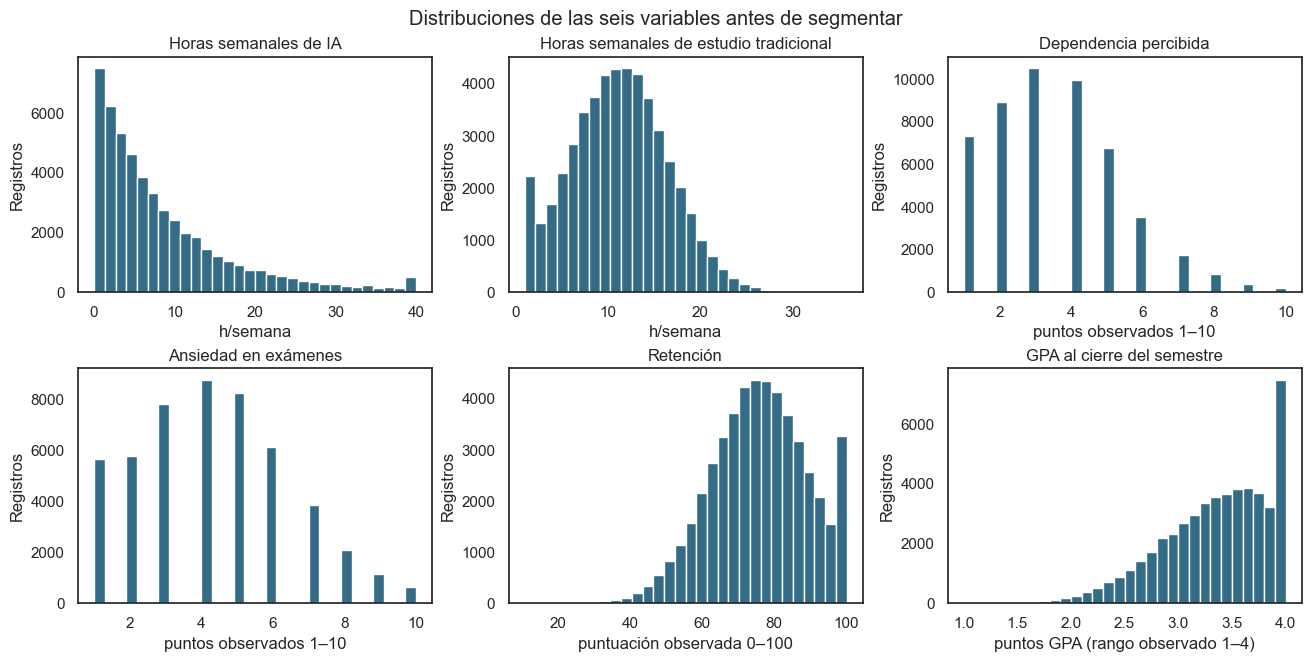

Las horas de IA presentan asimetría y una cola de usos intensivos; el GPA y la retención concentran registros cerca de sus extremos superiores observados. Estas formas influyen en las distancias y la interpretación de centroides. No permiten deducir cómo se generaron los datos ni probar un origen sintético.

IQR señala extremos, no errores automáticos. Se conservan los valores originales y todos los registros, incluidos usos intensivos pertinentes para el proyecto. K-Means y StandardScaler son sensibles a extremos; una futura sensibilidad a geometría y escalas requeriría otro análisis documentado, sin recortes por defecto.

In [3]:
VARIABLES = ['Weekly_GenAI_Hours', 'Traditional_Study_Hours', 'Perceived_AI_Dependency',
             'Anxiety_Level_During_Exams', 'Skill_Retention_Score', 'Post_Semester_GPA']
significados = ['Horas semanales de IA', 'Horas semanales de estudio tradicional',
                'Dependencia percibida', 'Ansiedad en exámenes', 'Retención', 'GPA al cierre del semestre']
unidades = ['h/semana', 'h/semana', 'puntos observados 1–10', 'puntos observados 1–10',
            'puntuación observada 0–100', 'puntos GPA (rango observado 1–4)']
display(pd.DataFrame({'Variable incluida': VARIABLES, 'Interpretación': significados, 'Unidad': unidades}))
display(pd.DataFrame([
    ('Student_ID / _row_id', 'Solo trazabilidad; no definen similitud sustantiva.'),
    ('Burnout_Risk_Level', 'Objetivo principal supervisado; únicamente contraste posterior.'),
    ('Pre_Semester_GPA', 'Evitar peso redundante con GPA final; correlación calculada abajo.'),
    ('Tool_Diversity / Paid_Subscription y cinco categóricas', 'Fuera de esta segmentación acotada de seis variables.'),
    ('GPA_Change', 'Propuesta secundaria diferente, no incorporada aquí.')
], columns=['Variable excluida', 'Motivo']))
assert not {'Student_ID', '_row_id', 'Burnout_Risk_Level'} & set(VARIABLES)
assert np.isfinite(df[VARIABLES].to_numpy()).all()
correlacion_gpa = df.Pre_Semester_GPA.corr(df.Post_Semester_GPA)
print(f'Pearson GPA previo–final: {correlacion_gpa:.6f}')
display(df[VARIABLES].describe().T.round(3))
display(Markdown(f'La correlación GPA previo–final es **{correlacion_gpa:.3f}**: incluir ambos '
                 'podría dar peso redundante al rendimiento en las distancias; se conserva GPA final por '
                 'el alcance retrospectivo. La correlación no prueba causalidad.'))

iqr_rows = []
for col in VARIABLES:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_rows.append({'Variable': col, 'Límite IQR inferior': low, 'Límite IQR superior': high,
                     'Marcados IQR': int(((df[col] < low) | (df[col] > high)).sum())})
display(pd.DataFrame(iqr_rows).round(3))
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), constrained_layout=True)
for ax, col, title, unit in zip(axes.flat, VARIABLES, significados, unidades):
    ax.hist(df[col], bins=30, color='#346B86', edgecolor='white')
    ax.set(title=title, xlabel=unit, ylabel='Registros')
fig.suptitle('Distribuciones de las seis variables antes de segmentar')
plt.show()
display(Markdown('Las horas de IA presentan asimetría y una cola de usos intensivos; '
                 'el GPA y la retención concentran registros cerca de sus extremos superiores observados. '
                 'Estas formas influyen en las distancias y la interpretación de centroides. '
                 'No permiten deducir cómo se generaron los datos ni probar un origen sintético.'))
display(Markdown('IQR señala extremos, no errores automáticos. Se conservan los valores originales '
                 'y todos los registros, incluidos usos intensivos pertinentes para el proyecto. '
                 'K-Means y StandardScaler son sensibles a extremos; una futura sensibilidad '
                 'a geometría y escalas requeriría otro análisis documentado, sin recortes por defecto.'))

In [4]:
scaler = StandardScaler()
X = scaler.fit_transform(df[VARIABLES])
assert X.shape == (N, 6) and np.isfinite(X).all()
assert np.allclose(X.mean(axis=0), 0, atol=1e-12)
assert np.allclose(X.std(axis=0, ddof=0), 1)
display(pd.DataFrame({'Variable': VARIABLES, 'Media original': scaler.mean_,
                      'DE original (ddof=0)': scaler.scale_,
                      'Media escalada': X.mean(axis=0), 'DE escalada (ddof=0)': X.std(axis=0)}).round(6))
display(Markdown('El escalado produce media aproximadamente cero y DE uno por variable. '
                 'Todas las filas se usan por el alcance descriptivo; estas matrices y parámetros '
                 'no alimentan CV ni reemplazan los preprocesadores de la clasificación.'))

,Variable,Media original,DE original (ddof=0),Media escalada,DE escalada (ddof=0)
0,Weekly_GenAI_Hours,8.427752,8.269407,-0.0,1.0
1,Traditional_Study_Hours,11.209271,5.156375,0.0,1.0
2,Perceived_AI_Dependency,3.505360,1.820794,-0.0,1.0
3,Anxiety_Level_During_Exams,4.270760,2.144045,-0.0,1.0
4,Skill_Retention_Score,75.798125,13.281493,0.0,1.0
5,Post_Semester_GPA,3.349299,0.495668,0.0,1.0


El escalado produce media aproximadamente cero y DE uno por variable. Todas las filas se usan por el alcance descriptivo; estas matrices y parámetros no alimentan CV ni reemplazan los preprocesadores de la clasificación.

## 5 · Comparación de k y decisión descriptiva

La inercia resume distancias cuadradas intragrupo; decrece al aumentar k. Silhouette compara
distancias dentro del grupo y al grupo vecino, con rango −1 a 1: valores próximos a cero indican
solapamiento. No hay un umbral universal que garantice utilidad ni equivale a Accuracy.

Se comparan modelos con los mismos parámetros y la misma muestra de silhouette. Se conservará
`k=3` como una resolución descriptiva para distinguir perfiles académicos entre registros de menor
uso de IA, siempre contrastando el resultado con `k=2`. No se decide k por concentración de High
ni porque existan tres clases supervisadas. No se declara un k óptimo universal.

,Inercia,Silhouette (muestra),Iteraciones
k,,,
2,238212.255091,0.241196,8
3,205988.095364,0.163155,13
4,188343.864403,0.145529,17
5,173972.697357,0.141557,26
6,163853.724318,0.137416,65


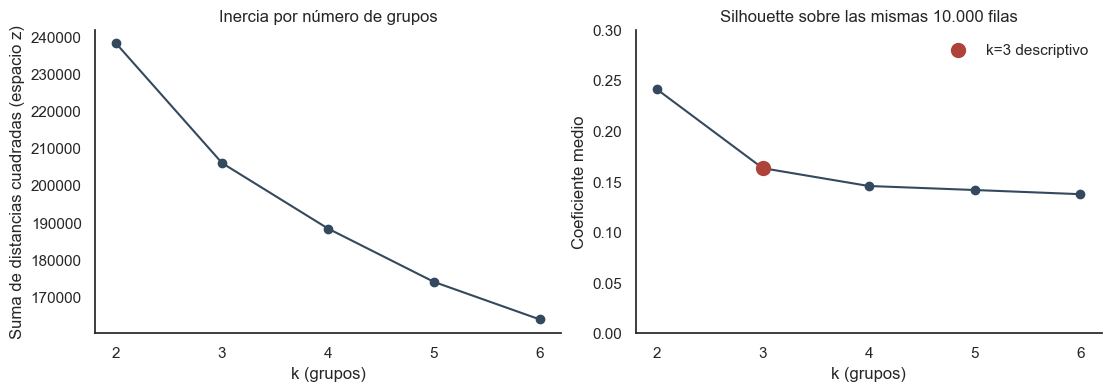

La mayor media silhouette entre los k evaluados corresponde a **k=2** (**0.241**). Para k=3 es **0.163**, lo que evidencia **separación limitada y solapamiento**. La curva de inercia por sí sola no establece un codo inequívoco ni justifica llamar óptimo a k=3.

,Cluster,k,Registros,Weekly_GenAI_Hours,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Skill_Retention_Score,Post_Semester_GPA
0,0,2,12865,18.668,9.377,5.600,5.798,72.323,3.306
1,1,2,37135,4.880,11.844,2.780,3.742,77.002,3.364
2,0,3,18209,5.048,8.866,2.795,3.738,69.542,3.033
3,1,3,9765,21.069,9.267,5.942,5.911,71.892,3.327
4,2,3,22026,5.618,14.007,3.012,3.984,82.702,3.621


Se mantiene **k=3 como elección descriptiva**, sacrificando separación frente a k=2. Permite distinguir dos perfiles de menor uso de IA con GPA medio **3.62 frente a 3.03**, y estudio tradicional **14.01 frente a 8.87 h/semana**. Estas diferencias son descriptivas de variables usadas para construir los grupos, no una validación independiente. Si el criterio fuera exclusivamente silhouette, se preferiría el mayor de los valores comparados.

In [5]:
muestra = np.random.RandomState(SEMILLA_MUESTRA).choice(N, min(10000, N), replace=False)
modelos_k, resultados = {}, []
for k in range(2, 7):
    with threadpool_limits(limits=1), config_context(working_memory=128):
        modelo = KMeans(n_clusters=k, init='k-means++', n_init=N_INIT,
                        random_state=SEED, max_iter=300, tol=1e-4).fit(X)
        sil = silhouette_score(X[muestra], modelo.labels_[muestra])
    assert modelo.n_iter_ < modelo.max_iter, 'Revisar convergencia antes de interpretar.'
    modelos_k[k] = modelo
    resultados.append({'k': k, 'Inercia': modelo.inertia_, 'Silhouette (muestra)': sil,
                        'Iteraciones': modelo.n_iter_})
res = pd.DataFrame(resultados).set_index('k')
display(res.round(6))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
axes[0].plot(res.index, res['Inercia'], 'o-', color='#34495E')
axes[0].set(title='Inercia por número de grupos', xlabel='k (grupos)',
            ylabel='Suma de distancias cuadradas (espacio z)')
axes[1].plot(res.index, res['Silhouette (muestra)'], 'o-', color='#34495E')
axes[1].scatter([K_ELEGIDO], [res.loc[K_ELEGIDO, 'Silhouette (muestra)']],
                s=100, color='#AD4339', label='k=3 descriptivo', zorder=3)
axes[1].set(title='Silhouette sobre las mismas 10.000 filas', xlabel='k (grupos)',
            ylabel='Coeficiente medio', ylim=(0, max(.30, res['Silhouette (muestra)'].max() * 1.15)))
axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xticks(res.index); sns.despine(ax=ax)
plt.show()
mejor_k_sil = int(res['Silhouette (muestra)'].idxmax())
km = modelos_k[K_ELEGIDO]  # Se reutiliza exactamente el modelo evaluado, sin otro ajuste.
sil_final = float(res.loc[K_ELEGIDO, 'Silhouette (muestra)'])
display(Markdown(f'La mayor media silhouette entre los k evaluados corresponde a **k={mejor_k_sil}** '
                 f'(**{res.loc[mejor_k_sil, "Silhouette (muestra)"]:.3f}**). Para k=3 es '
                 f'**{sil_final:.3f}**, lo que evidencia **separación limitada y solapamiento**. '
                 'La curva de inercia por sí sola no establece un codo inequívoco ni justifica llamar óptimo a k=3.'))

comparacion_perfiles = []
for k in [2, K_ELEGIDO]:
    resumen = df.groupby(modelos_k[k].labels_)[VARIABLES].mean()
    resumen.insert(0, 'Registros', pd.Series(modelos_k[k].labels_).value_counts())
    resumen.insert(0, 'k', k)
    resumen.index.name = 'Cluster'
    comparacion_perfiles.append(resumen.reset_index())
display(pd.concat(comparacion_perfiles, ignore_index=True).round(3))
# Identificar perfiles usando solo características, antes del contraste con la etiqueta.
medias = df.groupby(km.labels_)[VARIABLES].mean()
dep = int(medias.Perceived_AI_Dependency.idxmax())
alto = int(medias.Post_Semester_GPA.idxmax())
assert dep != alto, 'Revisar nombres: máximos de dependencia y GPA recaen en el mismo grupo.'
restantes = sorted(set(medias.index) - {dep, alto})
assert len(restantes) == 1
lig = int(restantes[0])
assert medias.loc[dep, 'Weekly_GenAI_Hours'] == medias.Weekly_GenAI_Hours.max()
NOMBRES = {alto: 'Menor uso de IA y mayor GPA', lig: 'Menor uso de IA y menor GPA',
           dep: 'Mayor uso de IA y dependencia percibida'}
CORTOS = {alto: 'Menor IA / mayor GPA', lig: 'Menor IA / menor GPA', dep: 'Mayor IA / dependencia'}
COLORES = {alto: '#2E7D5B', lig: '#7A8794', dep: '#AD4339'}
ORDEN = [alto, lig, dep]
display(Markdown(f'Se mantiene **k=3 como elección descriptiva**, sacrificando separación frente a k=2. '
                 f'Permite distinguir dos perfiles de menor uso de IA con GPA medio '
                 f'**{medias.loc[alto, "Post_Semester_GPA"]:.2f} frente a {medias.loc[lig, "Post_Semester_GPA"]:.2f}**, '
                 f'y estudio tradicional **{medias.loc[alto, "Traditional_Study_Hours"]:.2f} frente a '
                 f'{medias.loc[lig, "Traditional_Study_Hours"]:.2f} h/semana**. '
                 'Estas diferencias son descriptivas de variables usadas para construir los grupos, '
                 'no una validación independiente. Si el criterio fuera exclusivamente silhouette, '
                 'se preferiría el mayor de los valores comparados.'))

## 6 · Perfilado y contraste posterior con burnout

Los nombres resumen promedios relativos de este dataset. No diagnostican dependencia ni garantizan
equilibrio o bienestar individual. Las diferencias en las variables de entrada son parte de la propia
construcción del agrupamiento. Ahora, y únicamente para describir la asociación, se cruza la etiqueta.

**Denominadores distintos:** `% del total` divide por los 50.000 registros;
`% High dentro del perfil` divide por el tamaño del perfil;
`% de todos los High` divide por los 12.487 High del CSV. Ninguno es Accuracy de K-Means.

In [6]:
df['Cluster'] = km.labels_
df['Perfil'] = df.Cluster.map(NOMBRES)
es_high = df.Burnout_Risk_Level.eq('High')
perfil = df.groupby('Cluster').agg(
    Registros=('Student_ID', 'size'), IA_h=('Weekly_GenAI_Hours', 'mean'),
    Estudio_h=('Traditional_Study_Hours', 'mean'), Dependencia=('Perceived_AI_Dependency', 'mean'),
    Ansiedad=('Anxiety_Level_During_Exams', 'mean'), Retencion=('Skill_Retention_Score', 'mean'),
    GPA_final=('Post_Semester_GPA', 'mean'))
perfil['% del total'] = 100 * perfil.Registros / N
perfil['High_n'] = es_high.groupby(df.Cluster).sum()
perfil['% High dentro del perfil'] = 100 * perfil.High_n / perfil.Registros
perfil['% de todos los High'] = 100 * perfil.High_n / HIGH_TOTAL
perfil = perfil.loc[ORDEN]
perfil.index = [NOMBRES[c] for c in ORDEN]
display(perfil.round(3))
assert int(perfil.Registros.sum()) == N and int(perfil.High_n.sum()) == HIGH_TOTAL
kpi_reconstruido = np.average(perfil['% High dentro del perfil'], weights=perfil.Registros)
assert np.isclose(kpi_reconstruido, KPI, rtol=0, atol=1e-12)
dep_row = perfil.loc[NOMBRES[dep]]
high_fuera = HIGH_TOTAL - int(dep_row.High_n)
display(Markdown(f'El perfil de mayor uso de IA representa **{dep_row["% del total"]:.2f} %** del dataset. '
                 f'Dentro de él hay **{int(dep_row.High_n):,} etiquetas High**, equivalentes al '
                 f'**{dep_row["% High dentro del perfil"]:.2f} %** de sus registros y al '
                 f'**{dep_row["% de todos los High"]:.2f} %** de todos los High. '
                 f'Fuera permanecen **{high_fuera:,} High**; no es el único grupo relevante. '
                 f'El promedio ponderado de las tasas por perfil reconstruye el KPI: '
                 f'**{kpi_reconstruido:.3f} %**. No hubo reducción de etiquetas ni del riesgo real.'))
conteos_cruzados = pd.crosstab(df.Perfil, df.Burnout_Risk_Level).reindex(index=perfil.index, columns=CLASES)
porcentajes_cruzados = conteos_cruzados.div(conteos_cruzados.sum(axis=1), axis=0).mul(100)
display(conteos_cruzados)
display(porcentajes_cruzados.round(2))
display(Markdown('Todos los perfiles contienen Low, Medium y High. Cluster y clase supervisada '
                 'son conceptos distintos; no se asigna una correspondencia uno a uno entre ambos.'))

,Registros,IA_h,Estudio_h,Dependencia,Ansiedad,Retencion,GPA_final,% del total,High_n,% High dentro del perfil,% de todos los High
Menor uso de IA y mayor GPA,22026,5.618,14.007,3.012,3.984,82.702,3.621,44.052,3357,15.241,26.884
Menor uso de IA y menor GPA,18209,5.048,8.866,2.795,3.738,69.542,3.033,36.418,3281,18.019,26.275
Mayor uso de IA y dependencia percibida,9765,21.069,9.267,5.942,5.911,71.892,3.327,19.530,5849,59.898,46.841


El perfil de mayor uso de IA representa **19.53 %** del dataset. Dentro de él hay **5,849 etiquetas High**, equivalentes al **59.90 %** de sus registros y al **46.84 %** de todos los High. Fuera permanecen **6,638 High**; no es el único grupo relevante. El promedio ponderado de las tasas por perfil reconstruye el KPI: **24.974 %**. No hubo reducción de etiquetas ni del riesgo real.

Burnout_Risk_Level,Low,Medium,High
Menor uso de IA y mayor GPA,9016,9653,3357
Menor uso de IA y menor GPA,6610,8318,3281
Mayor uso de IA y dependencia percibida,743,3173,5849


Burnout_Risk_Level,Low,Medium,High
Menor uso de IA y mayor GPA,40.93,43.83,15.24
Menor uso de IA y menor GPA,36.30,45.68,18.02
Mayor uso de IA y dependencia percibida,7.61,32.49,59.90


Todos los perfiles contienen Low, Medium y High. Cluster y clase supervisada son conceptos distintos; no se asigna una correspondencia uno a uno entre ambos.

## 7 · Comunicación visual y hallazgo principal

Se mantiene la presentación por tarjetas y el contraste figura–fondo del borrador. La proximidad
agrupa indicadores dentro de cada tarjeta, la semejanza mantiene los mismos colores entre vistas
y una región común delimita cada perfil. El énfasis cromático destaca el perfil de mayor uso de IA,
sin representar una clasificación clínica ni una escala ordinal de los clústeres.

In [7]:
titulo = (f'El perfil de mayor uso de IA reúne el {dep_row["% del total"]:.2f} % de los registros '
          f'y concentra el {dep_row["% de todos los High"]:.2f} % de las etiquetas High')
def tarjeta(c):
    r = perfil.loc[NOMBRES[c]]
    fondo = '#FCEEEB' if c == dep else '#FFFFFF'
    return f'''<div style="flex:1 1 240px;min-width:0;background:{fondo};border:1px solid #CCD3DA;
    border-top:5px solid {COLORES[c]};border-radius:8px;padding:15px;box-sizing:border-box">
    <div style="font-size:16px;font-weight:700">{NOMBRES[c]}</div>
    <div style="font-size:12px;color:#4C5865;margin:8px 0">{int(r.Registros):,} registros · {r['% del total']:.2f} % del total</div>
    <div style="font-size:13px;line-height:1.6">IA: {r.IA_h:.2f} h/sem · Estudio: {r.Estudio_h:.2f} h/sem<br>
    Dependencia percibida: {r.Dependencia:.2f} puntos · Ansiedad: {r.Ansiedad:.2f} puntos<br>
    Retención: {r.Retencion:.2f} puntos · GPA final: {r.GPA_final:.2f}</div>
    <div style="font-size:14px;font-weight:700;margin-top:10px">Etiquetas High dentro del perfil: {r['% High dentro del perfil']:.2f} %</div>
    <div style="font-size:12px">{int(r.High_n):,} High · {r['% de todos los High']:.2f} % de todos los High</div></div>'''

html_tarjetas = f'''<section style="background:#F5F7FA;padding:20px;border-radius:8px;font-family:Arial,sans-serif;color:#182839">
<h3 style="margin-top:0">{titulo}</h3>
<p>Segmentación retrospectiva de {N:,} registros con seis variables. KPI global: {KPI:.3f} % de etiquetas High.</p>
<div style="display:flex;flex-wrap:wrap;gap:12px">{''.join(tarjeta(c) for c in ORDEN)}</div>
<div style="background:#203346;color:white;padding:14px;margin-top:14px;border-radius:8px;line-height:1.6">
<b>Hallazgo descriptivo:</b> la concentración de High difiere entre perfiles; fuera del destacado permanecen {high_fuera:,} High.<br>
<b>Propuestas para valorar en Fase 5:</b> estudiar la pertinencia de apoyo al uso responsable de IA y a los hábitos académicos,
sin excluir a otros grupos. Hacen falta evidencia externa, valoración de recursos y evaluación de intervenciones.<br>
No se demuestra que seleccionar un perfil permita detectar anticipadamente casos ni reducir el riesgo real.</div></section>'''
display(HTML(html_tarjetas))

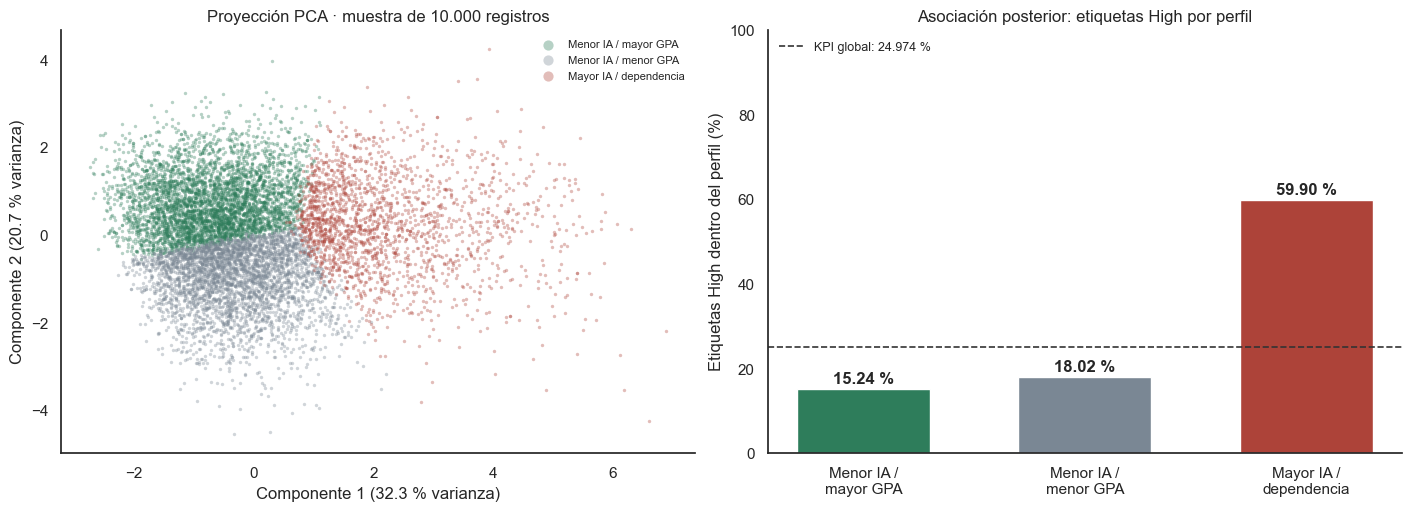

PCA se utiliza solo para visualizar: sus dos componentes conservan **53.03 %** de la varianza. K-Means se ajustó en las seis dimensiones estandarizadas, no en esta proyección. La separación visual no sustituye al silhouette. Las barras muestran proporciones de etiquetas observadas y la referencia global exacta, sin afirmar causalidad.

Fuente: Kaggle «AI Usage & Student Academic Performance Analysis» v1 (CC0); cálculo propio.


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
Z = PCA(n_components=2, random_state=SEED).fit(X)
coords = Z.transform(X)[muestra]
lab = df.Cluster.to_numpy()[muestra]
for c in ORDEN:
    ax[0].scatter(coords[lab == c, 0], coords[lab == c, 1], s=6, alpha=.35,
                  color=COLORES[c], label=CORTOS[c], linewidths=0)
ax[0].set(xlabel=f'Componente 1 ({Z.explained_variance_ratio_[0]*100:.1f} % varianza)',
          ylabel=f'Componente 2 ({Z.explained_variance_ratio_[1]*100:.1f} % varianza)',
          title='Proyección PCA · muestra de 10.000 registros')
ax[0].legend(frameon=False, markerscale=3, fontsize=8)
vals = perfil['% High dentro del perfil'].to_numpy()
barras = ax[1].bar(range(3), vals, color=[COLORES[c] for c in ORDEN], width=.6)
for b, v in zip(barras, vals):
    ax[1].text(b.get_x()+b.get_width()/2, v+1.3, f'{v:.2f} %', ha='center', fontweight='bold')
ax[1].axhline(KPI, color='#333333', ls='--', lw=1.2, label=f'KPI global: {KPI:.3f} %')
ax[1].set(xticks=range(3), xticklabels=['Menor IA /\nmayor GPA', 'Menor IA /\nmenor GPA', 'Mayor IA /\ndependencia'],
          ylim=(0, 100), ylabel='Etiquetas High dentro del perfil (%)', title='Asociación posterior: etiquetas High por perfil')
ax[1].legend(frameon=False, fontsize=9, loc='upper left')
for a in ax: sns.despine(ax=a)
plt.show()
varianza_2d = float(Z.explained_variance_ratio_.sum()*100)
display(Markdown(f'PCA se utiliza solo para visualizar: sus dos componentes conservan **{varianza_2d:.2f} %** '
                 'de la varianza. K-Means se ajustó en las seis dimensiones estandarizadas, no en esta proyección. '
                 'La separación visual no sustituye al silhouette. Las barras muestran proporciones de etiquetas '
                 'observadas y la referencia global exacta, sin afirmar causalidad.'))
print(FUENTE)

### 7.1 · Dispersión dentro de cada perfil

Los promedios de las tarjetas no describen a todas las personas por igual. Los siguientes boxplots
muestran mediana, cuartiles, bigotes hasta 1,5 IQR y valores señalados como extremos. Esos puntos
se mantienen en el análisis y no se clasifican automáticamente como errores.

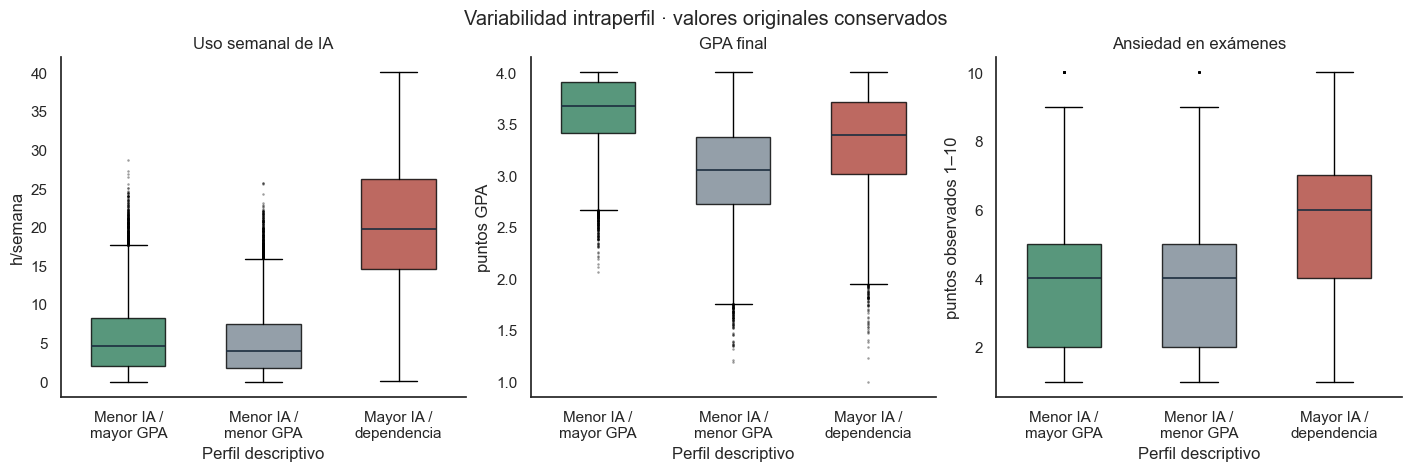

Los perfiles describen tendencias y mantienen variabilidad interna; sus nombres no asignan a cada registro una condición de bienestar. La distribución de etiquetas Low/Medium/High mostrada antes es el contraste pertinente para el objetivo del proyecto.

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), constrained_layout=True)
for ax, variable, title, unit in zip(axes,
        ['Weekly_GenAI_Hours', 'Post_Semester_GPA', 'Anxiety_Level_During_Exams'],
        ['Uso semanal de IA', 'GPA final', 'Ansiedad en exámenes'],
        ['h/semana', 'puntos GPA', 'puntos observados 1–10']):
    cajas = ax.boxplot([df.loc[df.Cluster.eq(c), variable].to_numpy() for c in ORDEN],
                       positions=range(3), widths=.55, patch_artist=True, orientation='vertical',
                       flierprops={'marker': '.', 'markersize': 1.5, 'alpha': .4},
                       medianprops={'color': '#1C2E3F', 'linewidth': 1.2})
    for caja, c in zip(cajas['boxes'], ORDEN):
        caja.set_facecolor(COLORES[c]); caja.set_alpha(.8)
    ax.set(title=title, xlabel='Perfil descriptivo', ylabel=unit)
    ax.set_xticks(range(3), ['Menor IA /\nmayor GPA', 'Menor IA /\nmenor GPA', 'Mayor IA /\ndependencia'])
    sns.despine(ax=ax)
fig.suptitle('Variabilidad intraperfil · valores originales conservados')
plt.show()
display(Markdown('Los perfiles describen tendencias y mantienen variabilidad interna; sus nombres '
                 'no asignan a cada registro una condición de bienestar. La distribución de etiquetas '
                 'Low/Medium/High mostrada antes es el contraste pertinente para el objetivo del proyecto.'))

## 8 · Estabilidad entre semillas y límites de validación

ARI compara dos asignaciones y no depende de cómo se numeran sus grupos. Uno significa
asignaciones idénticas; cerca de cero indica concordancia comparable a la esperada al azar.
Se compara el mismo CSV, las mismas variables y k=3 con tres semillas adicionales. Esta comprobación
evalúa sensibilidad a la inicialización, **no estabilidad de muestreo, generalización ni acierto sobre burnout**.

In [10]:
estabilidad = []
for semilla in [1, 7, 99]:
    with threadpool_limits(limits=1):
        otro = KMeans(n_clusters=K_ELEGIDO, init='k-means++', n_init=N_INIT,
                      random_state=semilla, max_iter=300, tol=1e-4).fit(X)
    estabilidad.append({'Semilla': semilla, 'ARI frente a base': adjusted_rand_score(km.labels_, otro.labels_),
                        'Inercia': otro.inertia_, 'Iteraciones': otro.n_iter_})
estabilidad = pd.DataFrame(estabilidad)
display(estabilidad.round(6))
display(Markdown(f'La concordancia entre las semillas evaluadas va de '
                 f'**{estabilidad["ARI frente a base"].min():.3f} a {estabilidad["ARI frente a base"].max():.3f}**. '
                 'El resultado es estable frente a estas inicializaciones, pero los grupos siguen teniendo '
                 f'separación limitada (silhouette **{sil_final:.3f}**). ARI no representa porcentaje '
                 'de burnout correctamente identificado ni reemplaza métricas del clasificador.'))

,Semilla,ARI frente a base,Inercia,Iteraciones
0,1,0.976717,205988.293958,19
1,7,0.981335,205987.907673,13
2,99,0.978778,205988.065776,11


La concordancia entre las semillas evaluadas va de **0.977 a 0.981**. El resultado es estable frente a estas inicializaciones, pero los grupos siguen teniendo separación limitada (silhouette **0.163**). ARI no representa porcentaje de burnout correctamente identificado ni reemplaza métricas del clasificador.

## 9 · Conclusiones calculadas y límites

Las cifras siguientes se generan a partir del modelo ejecutado. Las propuestas de actuación son
hipótesis para la evaluación posterior del proyecto; no recomendaciones clínicas ni intervenciones
cuya eficacia haya sido demostrada por este análisis.

In [11]:
assert np.array_equal(pd.util.hash_pandas_object(df[columnas_originales], index=True).to_numpy(), firma_original)
assert all(sha(ROOT / rel) == valor for rel, valor in huellas_antes.items()), 'Se alteró una entrada protegida.'
assert not {'Burnout_Risk_Level', 'Student_ID', '_row_id'} & set(VARIABLES)
assert scaler.n_features_in_ == 6 and km.n_features_in_ == 6
assert set(km.labels_) == {0, 1, 2} and not df.Perfil.isna().any()
assert np.isclose(perfil['% del total'].sum(), 100)
assert np.isclose(perfil['% de todos los High'].sum(), 100)
assert np.allclose(porcentajes_cruzados.sum(axis=1), 100)
display(Markdown(
    f'1. **Tres perfiles descriptivos**, definidos por seis variables estandarizadas y no por burnout. '
    f'El mayor silhouette comparado corresponde a k={mejor_k_sil}; se mantiene k=3 por la distinción académica adicional, '
    f'con separación limitada (**{sil_final:.3f}**).\n'
    f'2. **Hallazgo principal:** {int(dep_row.Registros):,} registros (**{dep_row["% del total"]:.2f} %**) '
    f'concentran {int(dep_row.High_n):,} etiquetas High (**{dep_row["% de todos los High"]:.2f} %** de todos los High). '
    f'La tasa High dentro de ese perfil es **{dep_row["% High dentro del perfil"]:.2f} %** frente al KPI '
    f'global de **{KPI:.3f} %**. Fuera quedan **{high_fuera:,} High**.\n'
    '3. **Relación con el proyecto:** complementa la comprensión de perfiles asociados a las etiquetas. '
    'No constituye un cuarto clasificador ni modifica los modelos principales.\n'
    '4. **Decisiones futuras:** contrastar pertinencia de apoyos, recursos, consecuencias de errores '
    'y evidencia externa en Fase 5. No se demuestra que las propuestas reduzcan el riesgo ni el KPI.\n'
    '5. **Integridad verificada:** cero registros o valores originales modificados/excluidos; '
    'CSV, particiones, manifiesto de Fase 3, selección y modelo final de Fase 4 conservan sus huellas.'
))
display(pd.DataFrame({'Comprobación': ['Valores originales', 'Registros conservados', 'Variables de K-Means',
                                      'KPI reconstruido', 'Huellas protegidas'],
                      'Resultado': ['Idénticos', str(N), str(len(VARIABLES)), f'{kpi_reconstruido:.3f} %', 'Coinciden']}))

1. **Tres perfiles descriptivos**, definidos por seis variables estandarizadas y no por burnout. El mayor silhouette comparado corresponde a k=2; se mantiene k=3 por la distinción académica adicional, con separación limitada (**0.163**).
2. **Hallazgo principal:** 9,765 registros (**19.53 %**) concentran 5,849 etiquetas High (**46.84 %** de todos los High). La tasa High dentro de ese perfil es **59.90 %** frente al KPI global de **24.974 %**. Fuera quedan **6,638 High**.
3. **Relación con el proyecto:** complementa la comprensión de perfiles asociados a las etiquetas. No constituye un cuarto clasificador ni modifica los modelos principales.
4. **Decisiones futuras:** contrastar pertinencia de apoyos, recursos, consecuencias de errores y evidencia externa en Fase 5. No se demuestra que las propuestas reduzcan el riesgo ni el KPI.
5. **Integridad verificada:** cero registros o valores originales modificados/excluidos; CSV, particiones, manifiesto de Fase 3, selección y modelo final de Fase 4 conservan sus huellas.

,Comprobación,Resultado
0,Valores originales,Idénticos
1,Registros conservados,50000
2,Variables de K-Means,6
3,KPI reconstruido,24.974 %
4,Huellas protegidas,Coinciden


### Límites que condicionan la interpretación

- `Burnout_Risk_Level` no es un diagnóstico clínico; no se documenta su fórmula ni se confirma el origen sintético.
  Las asociaciones con horas, dependencia y ansiedad podrían estar influidas por reglas desconocidas de
  construcción de la etiqueta. Excluirla del ajuste evita usarla directamente, pero no resuelve esa incertidumbre.
- El estudio es retrospectivo. GPA final, retención y los demás campos no acreditan disponibilidad anticipada.
  No se demuestran detección temprana, causalidad ni representatividad de una universidad.
- K-Means depende de variables, escalas, extremos y geometría euclidiana; impone una partición aunque no
  existan grupos naturales claramente separados. La concordancia entre semillas no prueba que existan tres
  tipos naturales de estudiante. No se hicieron pruebas de estabilidad ante remuestreo ni validación externa.
- Las seis variables cubren hábitos, bienestar y rendimiento. Las categorías y otros campos excluidos podrían
  aportar otras perspectivas; no se los declara irrelevantes ni se añade ingeniería de variables al clasificador.
- Fase 2 y esta exploración usan el CSV completo. Prueba sigue siendo una partición interna del experimento
  supervisado, no una cohorte externa nunca inspeccionada. Estos resultados no justifican retocar la selección
  congelada ni comparar nuevos modelos utilizando prueba.
- Los nombres son resúmenes relativos; no acreditan bienestar, dependencia clínica ni necesidad individual
  de intervención. Los costes y beneficios de las propuestas requieren evaluación adicional. Fase 5 permanece pendiente.

### Referencias y reproducción

Orden: reiniciar kernel y ejecutar todas las celdas desde la raíz o una subcarpeta del repositorio.
Usar Python 3.10.6 y scikit-learn 1.7.2 con `requirements.txt` y el lock existentes.
El único archivo de datos es `dataset/ai_student_impact_dataset (1).csv` (UTF-8, `;`);
su SHA-256 se muestra en la carga. No se guarda un dataset transformado ni se sobrescriben artefactos.

Estructura pedagógica contrastada con [el ejemplo de clase](h4_1_kmeans_ejemplo.ipynb): fundamento,
exploración, escalado, selección de k, agrupamiento, perfilado, comunicación y evaluación. El análisis
de EduAnalytics agrega el contraste posterior de etiquetas y los límites de su alcance.

Documentación oficial 1.7.2: [K-Means](https://scikit-learn.org/1.7/modules/generated/sklearn.cluster.KMeans.html),
[silhouette](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.silhouette_score.html),
[ARI](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.adjusted_rand_score.html),
[PCA](https://scikit-learn.org/1.7/modules/generated/sklearn.decomposition.PCA.html).